# Análisis de desviaciones · Real vs Presupuesto (ene–sep 2026)
**Distribuidora Atlántica, S.L.** — *empresa y datos ficticios*. Cifras en euros.

Preguntas que responde el notebook:
1. ¿Cómo va el EBITDA acumulado frente a presupuesto?
2. En ventas, ¿la desviación viene del **precio**, del **volumen** o del **mix** de productos?
3. ¿Qué partidas de gasto se han desviado más y en qué meses?
4. ¿Qué explica el paso del EBITDA presupuestado al real (cascada)?

Convención de signos: **Desviación = Real − Presupuesto**, con los gastos en negativo. Así, **positivo = favorable** en todas las líneas.

## 1 · Cargar datos y validarlos

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Usa los CSV locales si existen; si no, los descarga de GitHub
BASE = "https://raw.githubusercontent.com/jangostoc/finanzas-con-ia/main/03-desviaciones-real-vs-presupuesto/"
cargar = lambda f: pd.read_csv(f if os.path.exists(f) else BASE + f)
ventas, gastos = cargar("ventas.csv"), cargar("gastos.csv")

VERDE, ROJO, GRIS = "#1a7f37", "#cf222e", "#8c959f"
eur = lambda x: f"{x:,.0f} €".replace(",", ".")

# Validaciones básicas antes de analizar
for nombre, df, clave in [("ventas", ventas, ["mes", "linea", "escenario"]),
                          ("gastos", gastos, ["mes", "departamento", "concepto", "escenario"])]:
    print(f"{nombre:7s}: {len(df):3d} filas | meses {df.mes.min()} → {df.mes.max()} | "
          f"nulos: {df.isna().sum().sum()} | duplicados: {df.duplicated(clave).sum()} | "
          f"escenarios: {sorted(df.escenario.unique())}")
ventas.head()

ventas :  54 filas | meses 2026-01 → 2026-09 | nulos: 0 | duplicados: 0 | escenarios: ['Presupuesto', 'Real']
gastos : 216 filas | meses 2026-01 → 2026-09 | nulos: 0 | duplicados: 0 | escenarios: ['Presupuesto', 'Real']


,mes,linea,escenario,cajas,importe_ventas,coste_ventas
0,2026-01,Aceites,Presupuesto,22000,1056000.00,726000.00
1,2026-01,Aceites,Real,21564,1037562.09,698117.51
2,2026-02,Aceites,Presupuesto,20900,1003200.00,689700.00
3,2026-02,Aceites,Real,21629,1044818.72,782839.74
4,2026-03,Aceites,Presupuesto,22000,1056000.00,726000.00


## 2 · Cuenta de resultados acumulada: Real vs Presupuesto

In [2]:
v = ventas.groupby("escenario")[["importe_ventas", "coste_ventas"]].sum()
g = gastos.pivot_table(index="departamento", columns="escenario", values="importe", aggfunc="sum")

pyg = pd.DataFrame(columns=["Presupuesto", "Real"], dtype=float)
pyg.loc["Ventas"] = v["importe_ventas"]
pyg.loc["Coste de ventas"] = -v["coste_ventas"]
pyg.loc["Margen bruto"] = pyg.loc["Ventas"] + pyg.loc["Coste de ventas"]
for dep in ["Comercial", "Logística", "Administración", "IT"]:
    pyg.loc[f"  Gastos {dep}"] = -g.loc[dep]
pyg.loc["Gastos de estructura"] = pyg.loc[pyg.index.str.startswith("  Gastos")].sum()
pyg.loc["EBITDA"] = pyg.loc["Margen bruto"] + pyg.loc["Gastos de estructura"]

pyg["Desv €"] = pyg["Real"] - pyg["Presupuesto"]
pyg["Desv %"] = pyg["Desv €"] / pyg["Presupuesto"].abs() * 100

for e in ["Presupuesto", "Real"]:
    print(f"{e:12s} → margen bruto {pyg.loc['Margen bruto', e] / pyg.loc['Ventas', e]:.1%} | "
          f"margen EBITDA {pyg.loc['EBITDA', e] / pyg.loc['Ventas', e]:.1%}")

color = lambda x: f"color: {VERDE if x > 0 else ROJO}; font-weight: bold"
negrita = lambda r: ["font-weight: bold" if r.name in ("Margen bruto", "EBITDA") else ""] * len(r)
(pyg.style.format({"Presupuesto": "{:,.0f}", "Real": "{:,.0f}", "Desv €": "{:+,.0f}", "Desv %": "{:+.1f} %"})
    .map(color, subset=["Desv €", "Desv %"]).apply(negrita, axis=1))

Presupuesto  → margen bruto 35.6% | margen EBITDA 16.4%
Real         → margen bruto 34.5% | margen EBITDA 15.2%


,Presupuesto,Real,Desv €,Desv %
Ventas,"22,750,720","23,212,960","+462,240",+2.0 %
Coste de ventas,"-14,640,120","-15,208,527","-568,407",-3.9 %
Margen bruto,"8,110,600","8,004,433","-106,167",-1.3 %
Gastos Comercial,"-1,107,000","-1,131,894","-24,894",-2.2 %
Gastos Logística,"-2,182,086","-2,245,333","-63,247",-2.9 %
Gastos Administración,"-729,000","-719,970","+9,030",+1.2 %
Gastos IT,"-360,000","-382,906","-22,906",-6.4 %
Gastos de estructura,"-4,378,086","-4,480,103","-102,017",-2.3 %
EBITDA,"3,732,514","3,524,330","-208,184",-5.6 %


## 3 · Ventas y margen: efecto precio, volumen y mix
- **Volumen:** vendemos más o menos cajas en total.
- **Mix:** cambia el peso de cada línea (no es lo mismo vender una caja de aceite que una de bebidas).
- **Precio:** vendemos cada caja más cara o más barata.
- **Coste unitario** (solo en margen): cada caja nos cuesta más o menos.

In [3]:
y = ventas.groupby(["linea", "escenario"])[["cajas", "importe_ventas", "coste_ventas"]].sum().unstack()
Up, Ur = y["cajas"]["Presupuesto"], y["cajas"]["Real"]
Pp, Pr = y["importe_ventas"]["Presupuesto"] / Up, y["importe_ventas"]["Real"] / Ur
Cp, Cr = y["coste_ventas"]["Presupuesto"] / Up, y["coste_ventas"]["Real"] / Ur
peso_ppto = Up / Up.sum()

# --- Desviación de VENTAS ---
pvm = pd.DataFrame({
    "Cajas ppto": Up, "Cajas real": Ur,
    "Precio ppto €/caja": Pp, "Precio real €/caja": Pr,
    "Efecto volumen": (Ur.sum() * peso_ppto - Up) * Pp,
    "Efecto mix":     (Ur - Ur.sum() * peso_ppto) * Pp,
    "Efecto precio":  (Pr - Pp) * Ur,
})
pvm["Desv ventas"] = pvm[["Efecto volumen", "Efecto mix", "Efecto precio"]].sum(axis=1)
pvm.loc["TOTAL"] = pvm.sum(numeric_only=True)
pvm.loc["TOTAL", ["Precio ppto €/caja", "Precio real €/caja"]] = np.nan

# --- Desviación de MARGEN BRUTO (lo que de verdad importa) ---
margen = pd.DataFrame({
    "Coste ppto €/caja": Cp, "Coste real €/caja": Cr,
    "Volumen y mix": (Ur - Up) * (Pp - Cp),
    "Precio venta":  (Pr - Pp) * Ur,
    "Coste unitario": -(Cr - Cp) * Ur,
})
margen["Desv margen"] = margen[["Volumen y mix", "Precio venta", "Coste unitario"]].sum(axis=1)
margen.loc["TOTAL"] = margen.sum(numeric_only=True)
margen.loc["TOTAL", ["Coste ppto €/caja", "Coste real €/caja"]] = np.nan

# Comprobación: los efectos deben explicar el 100 % de la desviación
assert abs(pvm.loc["TOTAL", "Desv ventas"] - pyg.loc["Ventas", "Desv €"]) < 1
assert abs(margen.loc["TOTAL", "Desv margen"] - pyg.loc["Margen bruto", "Desv €"]) < 1
print("✅ Los efectos explican el 100 % de las desviaciones de ventas y margen")

fmt = lambda df: df.style.format("{:,.2f}", subset=[c for c in df if "€/caja" in c], na_rep="") \
                   .format("{:+,.0f}", subset=[c for c in df if "€/caja" not in c and "Cajas" not in c]) \
                   .format("{:,.0f}", subset=[c for c in df if "Cajas" in c]) \
                   .map(color, subset=[c for c in df if "€/caja" not in c and "Cajas" not in c])
display(fmt(pvm))
fmt(margen)

✅ Los efectos explican el 100 % de las desviaciones de ventas y margen


,Cajas ppto,Cajas real,Precio ppto €/caja,Precio real €/caja,Efecto volumen,Efecto mix,Efecto precio,Desv ventas
linea,,,,,,,,
Aceites,"195,140","188,872",48.00,50.70,"+40,999","-341,863","+509,133","+208,269"
Bebidas,"277,200","266,531",19.00,18.92,"+23,053","-225,764","-21,026","-223,737"
Conservas,"312,200","332,571",26.00,25.84,"+35,530","+494,116","-51,938","+477,708"
TOTAL,"784,540","787,974",,,"+99,582","-73,511","+436,169","+462,240"


,Coste ppto €/caja,Coste real €/caja,Volumen y mix,Precio venta,Coste unitario,Desv margen
linea,,,,,,
Aceites,33.00,35.82,"-94,020","+509,133","-533,197","-118,084"
Bebidas,11.00,11.00,"-85,352","-21,026",+568,"-105,810"
Conservas,16.50,16.57,"+193,524","-51,938","-23,861","+117,726"
TOTAL,,,"+14,152","+436,169","-556,489","-106,167"


## 4 · Gastos de estructura: ¿dónde están las desviaciones?

In [4]:
UMBRAL_EUR, UMBRAL_PCT = 10_000, 5      # criterio de materialidad: ambas condiciones

det = gastos.pivot_table(index=["departamento", "concepto"], columns="escenario", values="importe", aggfunc="sum")
det["Desv €"] = det["Presupuesto"] - det["Real"]           # gasto: gastar menos = favorable (+)
det["Desv %"] = det["Desv €"] / det["Presupuesto"] * 100
det["Alerta"] = np.where((det["Desv €"].abs() >= UMBRAL_EUR) & (det["Desv %"].abs() >= UMBRAL_PCT), "⚠️", "")
det = det.sort_values("Desv €")

print(f"Partidas que superan el umbral (≥ {eur(UMBRAL_EUR)} y ≥ {UMBRAL_PCT} %): {(det.Alerta != '').sum()} de {len(det)}")
(det.style.format({"Presupuesto": "{:,.0f}", "Real": "{:,.0f}", "Desv €": "{:+,.0f}", "Desv %": "{:+.1f} %"})
    .map(color, subset=["Desv €", "Desv %"]))

Partidas que superan el umbral (≥ 10.000 € y ≥ 5 %): 3 de 12


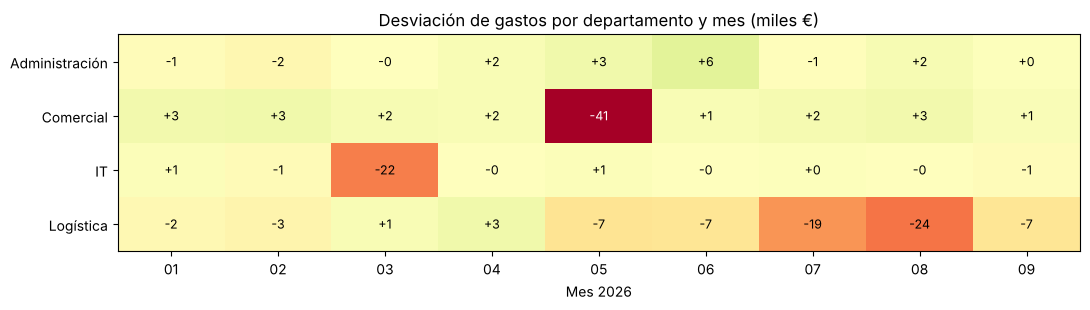

In [5]:
# Mapa de calor: desviación mensual por departamento (miles de €; verde = ahorro, rojo = sobrecoste)
mapa = (gastos.assign(signo=lambda d: np.where(d.escenario == "Presupuesto", 1, -1) * d.importe)
        .pivot_table(index="departamento", columns="mes", values="signo", aggfunc="sum") / 1000)

fig, ax = plt.subplots(figsize=(11, 3.2))
lim = np.abs(mapa.values).max()
ax.imshow(mapa.values, cmap="RdYlGn", vmin=-lim, vmax=lim, aspect="auto")
ax.set_xticks(range(len(mapa.columns)), [m[5:] for m in mapa.columns])
ax.set_yticks(range(len(mapa.index)), mapa.index)
for i in range(mapa.shape[0]):
    for j in range(mapa.shape[1]):
        ax.text(j, i, f"{mapa.iat[i, j]:+.0f}", ha="center", va="center", fontsize=9,
                color="white" if abs(mapa.iat[i, j]) > lim * 0.6 else "black")
ax.set_title("Desviación de gastos por departamento y mes (miles €)")
ax.set_xlabel("Mes 2026")
plt.tight_layout(); plt.show()

## 5 · Cascada: del EBITDA presupuestado al EBITDA real

✅ La cascada cuadra con el EBITDA real


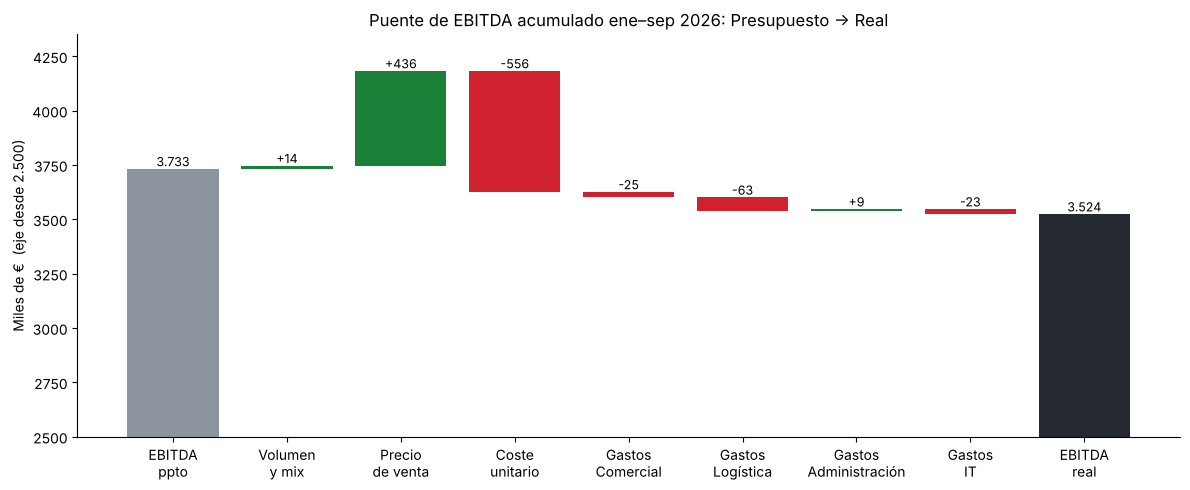

In [6]:
pasos = {
    "Volumen y mix":  margen.loc["TOTAL", "Volumen y mix"],
    "Precio de venta": margen.loc["TOTAL", "Precio venta"],
    "Coste unitario": margen.loc["TOTAL", "Coste unitario"],
}
for dep in ["Comercial", "Logística", "Administración", "IT"]:
    pasos[f"Gastos {dep}"] = det.loc[dep, "Desv €"].sum()

ini, fin = pyg.loc["EBITDA", "Presupuesto"], pyg.loc["EBITDA", "Real"]
assert abs(ini + sum(pasos.values()) - fin) < 1
print("✅ La cascada cuadra con el EBITDA real")

etiquetas = ["EBITDA\nppto"] + [k.replace(" ", "\n", 1) for k in pasos] + ["EBITDA\nreal"]
valores = [ini] + list(pasos.values()) + [fin]
bases, acum = [0], ini
for d in pasos.values():
    bases.append(acum if d >= 0 else acum + d); acum += d
bases.append(0)
alturas = [ini] + [abs(d) for d in pasos.values()] + [fin]
colores = [GRIS] + [VERDE if d >= 0 else ROJO for d in pasos.values()] + ["#24292f"]

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(etiquetas, [h / 1000 for h in alturas], bottom=[b / 1000 for b in bases], color=colores)
for i, (b, h, val) in enumerate(zip(bases, alturas, valores)):
    txt = f"{val / 1000:,.0f}" if i in (0, len(valores) - 1) else f"{val / 1000:+,.0f}"
    ax.text(i, (b + h) / 1000 + 12, txt.replace(",", "."), ha="center", fontsize=9)
niveles = [ini] + list(np.cumsum([ini] + list(pasos.values()))[1:])
suelo = np.floor(min(niveles) * 0.85 / 500_000) * 500_000      # eje recortado para que se vean las desviaciones
ax.set_ylim(suelo / 1000, max(b + h for b, h in zip(bases, alturas)) / 1000 * 1.04)
ax.set_ylabel(f"Miles de €  (eje desde {suelo / 1000:,.0f})".replace(",", "."))
ax.set_title("Puente de EBITDA acumulado ene–sep 2026: Presupuesto → Real")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

## 6 · Evolución mensual y exportación a Excel

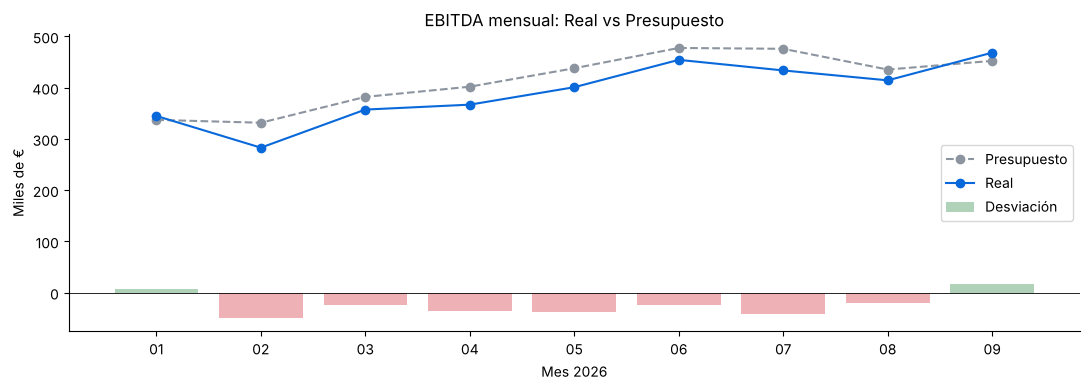

💾 Guardado informe_desviaciones_sep2026.xlsx (5 pestañas)


In [7]:
vm = ventas.groupby(["mes", "escenario"])[["importe_ventas", "coste_ventas"]].sum()
gm = gastos.groupby(["mes", "escenario"])["importe"].sum()
mensual = (vm["importe_ventas"] - vm["coste_ventas"] - gm).unstack("escenario")
mensual["Desv €"] = mensual["Real"] - mensual["Presupuesto"]

fig, ax = plt.subplots(figsize=(11, 4))
x = [m[5:] for m in mensual.index]
ax.plot(x, mensual["Presupuesto"] / 1000, color=GRIS, marker="o", linestyle="--", label="Presupuesto")
ax.plot(x, mensual["Real"] / 1000, color="#0969da", marker="o", label="Real")
ax.bar(x, mensual["Desv €"] / 1000, color=[VERDE if d >= 0 else ROJO for d in mensual["Desv €"]], alpha=.35, label="Desviación")
ax.axhline(0, color="black", linewidth=.6)
ax.set_ylabel("Miles de €"); ax.set_xlabel("Mes 2026")
ax.set_title("EBITDA mensual: Real vs Presupuesto"); ax.legend()
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

# ---- Excel con formato: números con separador, desviaciones en verde/rojo ----
from openpyxl.styles import Font
SALIDA = "informe_desviaciones_sep2026.xlsx"
hojas = {"PyG acumulada": pyg, "Precio-Volumen-Mix": pvm, "Margen por efectos": margen,
         "Gastos detalle": det, "EBITDA mensual": mensual}
with pd.ExcelWriter(SALIDA, engine="openpyxl") as w:
    for nombre, df in hojas.items():
        df.round(2).to_excel(w, sheet_name=nombre)
        ws = w.sheets[nombre]
        cab = [c.value for c in ws[1]]
        for col in ws.iter_cols(min_row=2):
            titulo = str(cab[col[0].column - 1])
            for celda in col:
                if isinstance(celda.value, (int, float)):
                    celda.number_format = "0.0" if "%" in titulo else ("#,##0.00" if "€/caja" in titulo else "#,##0")
                    if "Desv" in titulo or "Efecto" in titulo or titulo in ("Volumen y mix", "Precio venta", "Coste unitario"):
                        celda.font = Font(color=(VERDE if celda.value >= 0 else ROJO)[1:], bold=True)
        for col in ws.columns:
            ws.column_dimensions[col[0].column_letter].width = max(12, max(len(str(c.value or "")) for c in col) + 2)
print(f"💾 Guardado {SALIDA} ({len(hojas)} pestañas)")

## 7 · Conclusiones

**Vender más no ha significado ganar más.** Las ventas superan el presupuesto en **+462 k€ (+2,0 %)**, pero el EBITDA acumulado queda en **3.524 k€ frente a 3.733 k€: −208 k€ (−5,6 %)**. El margen EBITDA baja del 16,4 % al 15,2 %.

| Foco | Qué ha pasado | Impacto en EBITDA | ¿Controlable? |
|---|---|---|---|
| 🫒 **Aceites** | El coste por caja sube un 8,5 % (materia prima). Se repercute con +5,6 % de precio, pero se pierde un 3,2 % de volumen. | **−118 k€** | Parcialmente: política de precios y compras |
| 🥫 **Conservas** | Nuevo cliente: +6,5 % de cajas a cambio de un descuento del 2 %. | **+118 k€** | Sí: decisión comercial acertada |
| 🥤 **Bebidas** | Verano lluvioso: caída de volumen en julio y agosto. | **−106 k€** | No: factor externo |
| 🏢 **Gastos de estructura** | Campaña de marketing de mayo (−43 k€), licencias IT de marzo (−22 k€), horas extra y gasóleo en logística. Lo compensa en parte el ahorro en viajes (+14 k€). | **−102 k€** | Sí |

**Acciones propuestas**
1. **Aceites:** revisar la tarifa y negociar coberturas de precio de la materia prima para el 4º trimestre.
2. **Reforecast del 4º trimestre:** incorporar el nuevo cliente de conservas y la renovación anual de licencias IT, que deben estar en el presupuesto del próximo año.
3. **Logística:** analizar si las horas extra de verano justifican un refuerzo temporal planificado en lugar de horas extra.

*Criterio de materialidad aplicado: se señalan las partidas con desviación ≥ 10.000 € y ≥ 5 % a la vez. Por eso la energía (−7,2 %, pero solo −9 k€) no salta como alerta.*